# IMP302m – Object Counting and Size Classification with Classical Image Processing

**End-to-end demo notebook** · Course IMP302m – Image and Video Processing, FPT University

| Member | Email |
|---|---|
| Ngô Quang Huy | ngoquanghuy2k5@gmail.com |
| Nguyễn Đức Mạnh | Manhndse180326@fpt.edu.vn |
| Hoàng Văn Anh | anhhvse180142@fpt.edu.vn |

This notebook runs the whole project from start to finish and reproduces the numbers of the report:

1. Setup
2. Datasets (4 synthetic cases, 960 real photos)
3. Stage 1 – Preprocessing (gray conversion, histogram, AOD, FSHS, median/Gaussian denoising)
4. Stage 2 – Segmentation (Otsu, K-Means) and binary morphology
5. Stage 3 – Region labeling, watershed splitting and feature extraction
6. Stage 4 – Large/Small classification
7. Full pipeline on the 4 synthetic cases (count, classes, mask IoU)
8. Verification of the from-scratch implementations against OpenCV
9. Real photos: why the baseline fails and how the real-image branch works
10. Evaluation on the 480-image real test split (baseline A vs final V)
11. Results per real-image case (R1–R4) and counting-error distribution
12. Ablation on the dev split (how each step contributes)
13. Successes and failures
14. Run time: own NumPy implementations vs OpenCV
15. Try it on your own photo
16. Summary

The pipeline is **training-free**: every step is a classical image-processing operation, and the core algorithms are implemented from scratch in NumPy (package `ipm/`).

**Requirements:** `pip install -r requirements.txt` plus `ipykernel` to run notebooks. A full run takes about 5–10 minutes on a multi-core CPU (sections 10 and 12 process 480 images several times).

## 1. Setup

The notebook finds the repository root automatically, so it can be opened from the repository folder or any sub-folder.

In [1]:
import copy
import csv
import html
import json
import os
import platform
import sys
import time
from concurrent.futures import ProcessPoolExecutor
from dataclasses import replace
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import skimage
from IPython.display import HTML, display

# Locate the repository root (the folder that contains the ipm package)
ROOT = Path.cwd().resolve()
while not (ROOT / "ipm").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook from inside the IMP302 repository")
    ROOT = ROOT.parent
for p in (ROOT, ROOT / "tools"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from ipm import Config, run
from ipm import classify as clf
from ipm import labeling as lab
from ipm import morphology as morph
from ipm import preprocess as pre
from ipm import segmentation as seg
from ipm.evaluate import evaluate_image, load_ground_truth
from ipm.split import split_touching
from ipm.visualize import colorize_labels, draw_detections, iou
from main import REAL_PRESET, aggregate

# ipm.visualize selects the non-interactive Agg backend for batch runs; switch back to inline plots
%matplotlib inline

SYN = ROOT / "data" / "synthetic"
REAL = ROOT / "data" / "real" / "hf_coins"
N_WORKERS = max(1, min(8, (os.cpu_count() or 2) - 1))   # parallel workers for the 480-image evaluations

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

print(f"Repository : {ROOT}")
print(f"Python     : {platform.python_version()}  |  NumPy {np.__version__}  |  OpenCV {cv2.__version__}"
      f"  |  scikit-image {skimage.__version__}  |  Matplotlib {matplotlib.__version__}")
print(f"Workers    : {N_WORKERS}")

Repository : C:\Users\nguye\FPT\IPM
Python     : 3.14.7  |  NumPy 2.5.4  |  OpenCV 5.0.0  |  scikit-image 0.26.0  |  Matplotlib 3.11.2
Workers    : 8


Small helpers for showing images and tables. Gray images are always shown on a fixed 0–255 scale (and binary masks on 0–1), so a low-contrast image really looks low-contrast.

In [2]:
GT_BGR, PRED_BGR = (72, 73, 227), (214, 120, 42)   # red = ground truth, blue = prediction


def rgb(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def show(panels, cols=None, size=3.4, suptitle=None):
    """panels: list of (image, title). Color images are BGR; gray uses 0..255, binary masks 0..1."""
    cols = cols or len(panels)
    rows = -(-len(panels) // cols)
    first = panels[0][0]
    aspect = first.shape[0] / first.shape[1]
    fig, axs = plt.subplots(rows, cols, figsize=(size * cols, size * aspect * rows + 0.45 * rows), squeeze=False)
    for ax in axs.ravel():
        ax.axis("off")
    for ax, (im, title) in zip(axs.ravel(), panels):
        if im.ndim == 3:
            ax.imshow(rgb(im))
        else:
            ax.imshow(im, cmap="gray", vmin=0, vmax=1 if im.max() <= 1 else 255)
        ax.set_title(title)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    fig.tight_layout()
    plt.show()


def _fmt(v):
    if isinstance(v, (bool, np.bool_)):
        return "✓" if v else "✗"
    if isinstance(v, (float, np.floating)):
        return f"{v:.3f}"
    return html.escape(str(v))


def table(rows, columns=None):
    """Render a list of dicts as an HTML table."""
    columns = columns or list(rows[0])
    head = "".join(f"<th>{html.escape(str(c))}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{_fmt(r.get(c, ''))}</td>" for c in columns) + "</tr>" for r in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


def draw_boxes(img, gt_boxes=(), objects=(), scale=1.0):
    """Ground-truth boxes (red, COCO [x, y, w, h] in original coordinates) and predicted objects (blue)."""
    out = img.copy()
    for x, y, w, h in gt_boxes:
        x, y, w, h = (int(round(v * scale)) for v in (x, y, w, h))
        cv2.rectangle(out, (x, y), (x + w, y + h), GT_BGR, 2)
    for o in objects:
        cv2.rectangle(out, (o.x - 3, o.y - 3), (o.x + o.w + 2, o.y + o.h + 2), PRED_BGR, 2)
    return out


def timed(fn, *args, repeat=3, **kw):
    """Return (result, best time in ms over `repeat` runs)."""
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        out = fn(*args, **kw)
        best = min(best, (time.perf_counter() - t0) * 1000)
    return out, best

## 2. Datasets

### 2.1 Synthetic images – 4 controlled cases

Generated by `tools/generate_synthetic.py` (1600×1067 px, 3 large gold coins + 3 small silver coins). Each case deliberately stresses one stage of the pipeline, and the ground truth includes a **pixel-exact mask**, so the segmentation IoU can be measured.

| Case | Challenge | Stage that must handle it |
|---|---|---|
| Case 1 – Ideal | uniform white background | baseline |
| Case 2 – Low contrast | gray levels squeezed into [30, 100] | FSHS |
| Case 3 – Noise & glare | dust, hairs, salt-and-pepper noise, glare spots | median filter + morphology + hole filling |
| Case 4 – Overlapping | two small coins overlap | watershed |

image,size,objects,large,small,GT mask
case1_ideal.jpg,1600×1067,6,3,3,gt/case1_ideal_mask.png
case2_low_contrast.jpg,1600×1067,6,3,3,gt/case2_low_contrast_mask.png
case3_noisy_glare.jpg,1600×1067,6,3,3,gt/case3_noisy_glare_mask.png
case4_overlapping.jpg,1600×1067,6,3,3,gt/case4_overlapping_mask.png


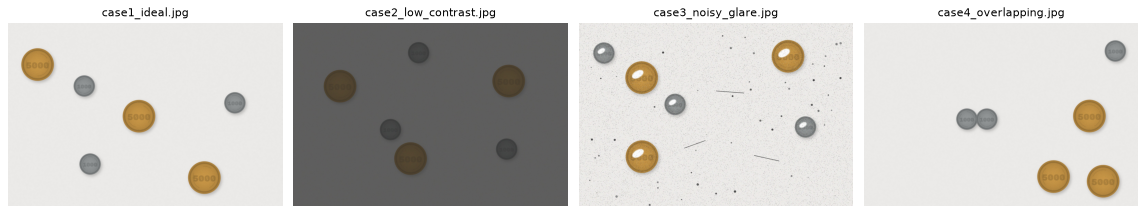

In [3]:
gt_syn = load_ground_truth(SYN / "ground_truth.json")
syn_imgs = {name: pre.load_image(SYN / name) for name in gt_syn}

table([{"image": n, "size": f"{syn_imgs[n].shape[1]}×{syn_imgs[n].shape[0]}", "objects": g["count"],
        "large": g["large"], "small": g["small"], "GT mask": g["mask"]} for n, g in gt_syn.items()])
show([(img, name) for name, img in syn_imgs.items()], cols=4, size=3.6)

### 2.2 Real photos – Roboflow 100 *coins-1apki* (CC BY 4.0)

Smartphone photos on many backgrounds (wood, gray desk, green mat, yellow paper), resized to 640×640. `tools/import_hf_coins.py` kept the **960 images that contain only coins (3–30 per image)** and split them randomly into **dev 480 / test 480** (seed 2026). Parameters are chosen on dev; test is used only for the final numbers.

The labels are bounding boxes, so counting and localization (Precision/Recall/F1) can be evaluated, but **not** Large/Small (the dataset has no size labels).

Each image is also assigned to one of **4 real-image cases** by `tools/real_cases.py`, using only ground truth and image statistics (never the algorithm output):
R4 touching coins > R3 textured background (top 30% roughness) > R2 low contrast (bottom 30% coin–background Lab difference) > R1 ideal.

Images: 960  (dev 480, test 480)
Coins : 6808 in total, 3–9 per image (median 7)


case,dev,test,test coins
R1 – Ideal,245,232,1745
R2 – Low contrast,73,88,599
R3 – Textured background,143,132,847
R4 – Touching coins,19,28,195


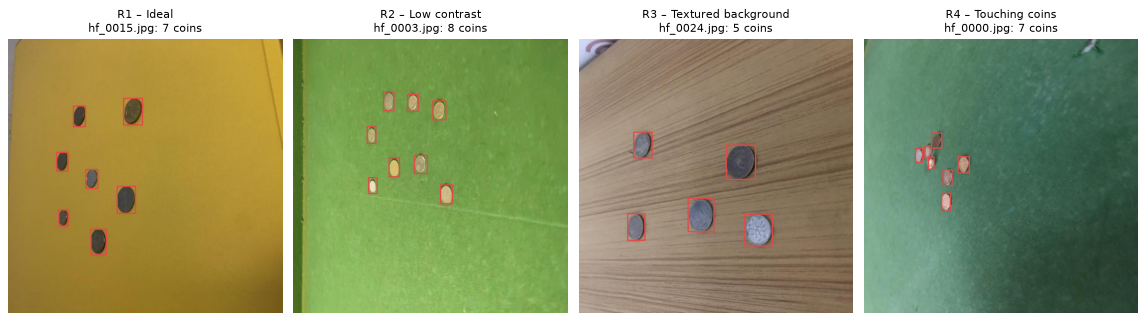

In [4]:
gt_real = load_ground_truth(REAL / "ground_truth.json")
split = json.loads((REAL / "split.json").read_text(encoding="utf-8"))
with open(ROOT / "report" / "data" / "real_cases.csv", encoding="utf-8") as f:
    cases = {r["image"]: int(r["case"]) for r in csv.DictReader(f)}
CASE_NAMES = {1: "R1 – Ideal", 2: "R2 – Low contrast", 3: "R3 – Textured background", 4: "R4 – Touching coins"}

counts = np.array([g["count"] for g in gt_real.values()])
print(f"Images: {len(gt_real)}  (dev {len(split['dev'])}, test {len(split['test'])})")
print(f"Coins : {counts.sum()} in total, {counts.min()}–{counts.max()} per image (median {np.median(counts):.0f})")
table([{"case": CASE_NAMES[k],
        "dev": sum(cases[n] == k for n in split["dev"]),
        "test": sum(cases[n] == k for n in split["test"]),
        "test coins": sum(gt_real[n]["count"] for n in split["test"] if cases[n] == k)} for k in CASE_NAMES])

# First test image of each case, with its ground-truth boxes (red)
examples = {k: next(n for n in split["test"] if cases[n] == k) for k in CASE_NAMES}
show([(draw_boxes(pre.load_image(REAL / n), gt_real[n]["boxes"]), f"{CASE_NAMES[k]}\n{n}: {gt_real[n]['count']} coins")
      for k, n in examples.items()], cols=4, size=3.6)

## 3. Stage 1 – Gray-level preprocessing

### 3.1 Resize, gray conversion, histogram and FSHS (Case 2 – low contrast)

* **Resize** to a working width of 800 px (scale factor $s$ is kept to map results back).
* **Gray conversion** (BT.601 luminance): $f = 0.299R + 0.587G + 0.114B$.
* **AOD** (average optical density) = mean gray level.
* **Full-Scale Histogram Stretch**: $g = \frac{K-1}{B-A}(f-A)$ with $A, B$ = 0.5th / 99.5th percentiles (robust to a few outliers).

Resized 1600 -> 800 px (s = 0.500)
Gray range before FSHS: [58, 98]   A = 62, B = 96
AOD before = 92.3   AOD after = 227.2


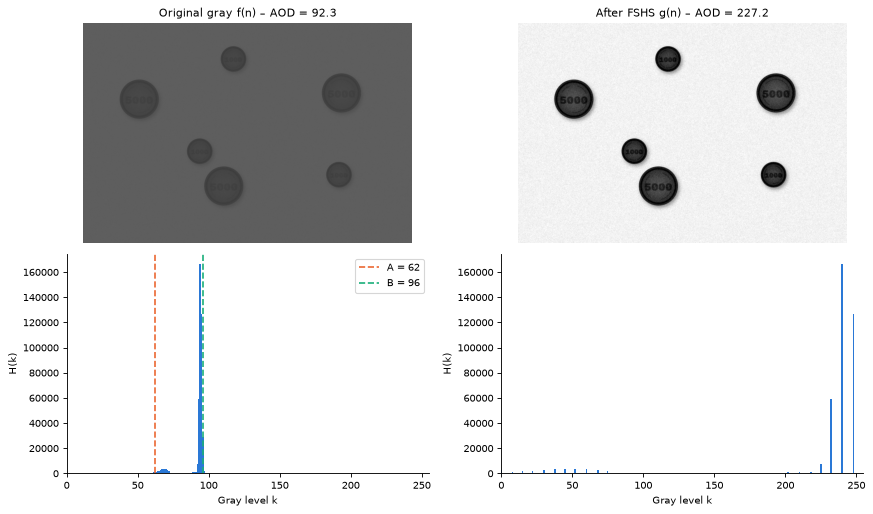

In [5]:
cfg = Config()                    # default configuration, numpy backend = own implementations
img2, s2 = pre.resize_to_width(syn_imgs["case2_low_contrast.jpg"], cfg.work_width)
gray2 = pre.rgb_to_gray(img2)
fshs2, A, B = pre.fshs(gray2, cfg.fshs_low_pct, cfg.fshs_high_pct)

print(f"Resized {syn_imgs['case2_low_contrast.jpg'].shape[1]} -> {img2.shape[1]} px (s = {s2:.3f})")
print(f"Gray range before FSHS: [{gray2.min()}, {gray2.max()}]   A = {A:.0f}, B = {B:.0f}")
print(f"AOD before = {pre.aod(gray2):.1f}   AOD after = {pre.aod(fshs2):.1f}")

fig, axs = plt.subplots(2, 2, figsize=(11, 6.5))
for col, (im, name) in enumerate([(gray2, "Original gray f(n)"), (fshs2, "After FSHS g(n)")]):
    axs[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axs[0, col].set_title(f"{name} – AOD = {pre.aod(im):.1f}")
    axs[0, col].axis("off")
    axs[1, col].bar(np.arange(256), pre.histogram(im), width=1.0, color=BLUE)
    axs[1, col].set_xlim(0, 255)
    axs[1, col].set_xlabel("Gray level k")
    axs[1, col].set_ylabel("H(k)")
axs[1, 0].axvline(A, color=ORANGE, ls="--", label=f"A = {A:.0f}")
axs[1, 0].axvline(B, color=GREEN, ls="--", label=f"B = {B:.0f}")
axs[1, 0].legend()
fig.tight_layout()
plt.show()

### 3.2 Denoising: median first, then Gaussian (Case 3 – noise & glare)

The median filter removes impulse (salt-and-pepper) noise; the Gaussian then smooths sensor noise. The order matters: a Gaussian applied first would smear each impulse over its neighborhood. The effect is measured by the number of connected regions after Otsu thresholding (the true number of objects is 6).

denoising,Otsu T*,regions after thresholding
no filtering,152,11346
Gaussian only,141,59
median only,140,44
median → Gaussian,143,35


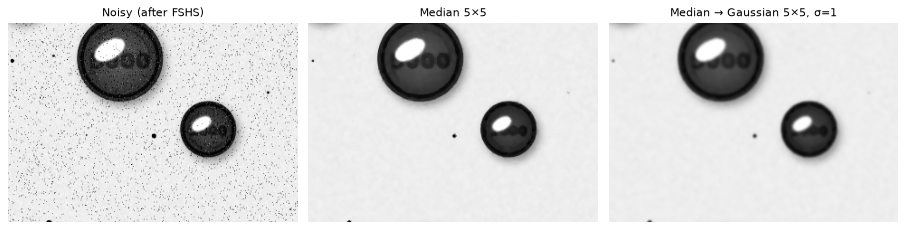

In [6]:
img3, _ = pre.resize_to_width(syn_imgs["case3_noisy_glare.jpg"], cfg.work_width)
g3 = pre.fshs(pre.rgb_to_gray(img3), cfg.fshs_low_pct, cfg.fshs_high_pct)[0]
med3 = pre.median_filter(g3, cfg.median_ksize)
smooth3 = pre.gaussian_filter(med3, cfg.gaussian_ksize, cfg.gaussian_sigma)
gau_only = pre.gaussian_filter(g3, cfg.gaussian_ksize, cfg.gaussian_sigma)

rows = []
for name, im in [("no filtering", g3), ("Gaussian only", gau_only), ("median only", med3), ("median → Gaussian", smooth3)]:
    T, _ = seg.otsu_threshold(im)
    mask = seg.threshold_mask(im, T, seg.background_is_bright(im, T))
    rows.append({"denoising": name, "Otsu T*": T, "regions after thresholding": lab.count_components(mask)})
table(rows)

y0, x0 = 120, 60          # zoom on a noisy corner
crop = lambda im: im[y0:y0 + 220, x0:x0 + 320]
show([(crop(g3), "Noisy (after FSHS)"), (crop(med3), "Median 5×5"), (crop(smooth3), "Median → Gaussian 5×5, σ=1")],
     size=3.8)

## 4. Stage 2 – Segmentation and binary morphology

### 4.1 Otsu and K-Means (Case 1)

**Otsu** chooses $T^* = \arg\max_t \sigma_b^2(t)$, with $\sigma_b^2 = w_0 w_1 (\mu_0-\mu_1)^2$.
**K-Means** (k = 2) on the gray levels converges to the midpoint of the two cluster means (the Ridler–Calvard fixed point). The **polarity** is detected automatically from the image border, which is almost always background.

Otsu    T* = 148
K-Means T  = 148  (centers [ 47.3 250. ], 3 iterations)
Background is bright -> objects are the dark class
IoU(Otsu mask, K-Means mask) = 1.0000


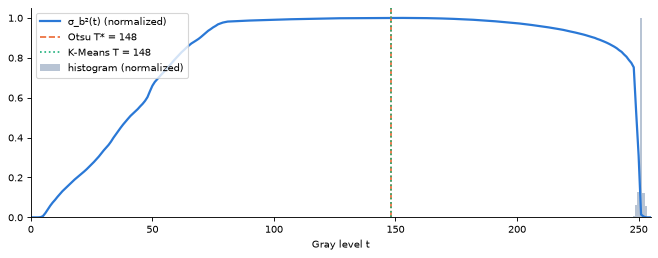

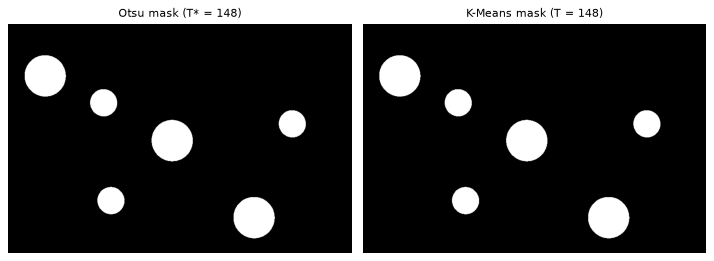

In [7]:
res1 = run(syn_imgs["case1_ideal.jpg"], cfg)
sm1 = res1.smooth
T_otsu, sigma_b = seg.otsu_threshold(sm1)
T_km, centers, iters = seg.kmeans_threshold(sm1)
bg_bright = seg.background_is_bright(sm1, T_otsu)
m_otsu = seg.threshold_mask(sm1, T_otsu, bg_bright)
m_km = seg.threshold_mask(sm1, T_km, bg_bright)

print(f"Otsu    T* = {T_otsu}")
print(f"K-Means T  = {T_km}  (centers {centers.round(1)}, {iters} iterations)")
print(f"Background is {'bright' if bg_bright else 'dark'} -> objects are the {'dark' if bg_bright else 'bright'} class")
print(f"IoU(Otsu mask, K-Means mask) = {iou(m_otsu, m_km):.4f}")

fig, ax = plt.subplots(figsize=(10, 3.4))
H = pre.histogram(sm1)
ax.bar(np.arange(256), H / H.max(), width=1.0, color="#b8c4d4", label="histogram (normalized)")
ax.plot(np.arange(256), sigma_b / sigma_b.max(), color=BLUE, lw=2, label="σ_b²(t) (normalized)")
ax.axvline(T_otsu, color=ORANGE, ls="--", lw=1.5, label=f"Otsu T* = {T_otsu}")
ax.axvline(T_km, color=GREEN, ls=":", lw=1.5, label=f"K-Means T = {T_km}")
ax.set_xlim(0, 255)
ax.set_xlabel("Gray level t")
ax.legend(loc="upper left")
plt.show()
show([(m_otsu, f"Otsu mask (T* = {T_otsu})"), (m_km, f"K-Means mask (T = {T_km})")], size=4.5)

### 4.2 Why FSHS matters for a fixed threshold but not for Otsu (Case 2)

FSHS is a linear map of the gray levels. A **fixed** threshold (T = 128) fails completely on the dark Case 2 image and only works after FSHS. **Otsu** is invariant to linear transforms: it moves its threshold together with the histogram, so its mask is identical before and after FSHS.

input,fixed T=128: regions,Otsu T*,Otsu: regions
before FSHS,1,80,6
after FSHS,6,135,6


IoU(Otsu before FSHS, Otsu after FSHS)   = 1.000
IoU(fixed before FSHS, fixed after FSHS) = 0.072


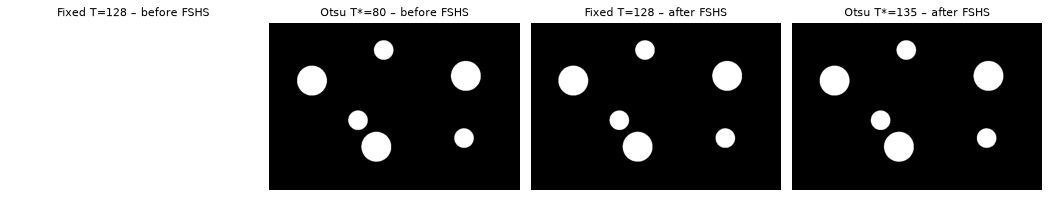

In [8]:
res2 = run(syn_imgs["case2_low_contrast.jpg"], cfg)
bg = res2.seg_info["background_bright"]            # polarity found by the pipeline (bright paper)
rows, panels = [], []
for name, im in [("before FSHS", res2.gray), ("after FSHS", res2.contrast)]:
    fixed = seg.threshold_mask(im, 128, bg)
    T, _ = seg.otsu_threshold(im)
    otsu = seg.threshold_mask(im, T, bg)
    rows.append({"input": name, "fixed T=128: regions": lab.count_components(fixed),
                 "Otsu T*": T, "Otsu: regions": lab.count_components(otsu)})
    panels += [(fixed, f"Fixed T=128 – {name}"), (otsu, f"Otsu T*={T} – {name}")]
table(rows)
print(f"IoU(Otsu before FSHS, Otsu after FSHS)   = {iou(panels[1][0], panels[3][0]):.3f}")
print(f"IoU(fixed before FSHS, fixed after FSHS) = {iou(panels[0][0], panels[2][0]):.3f}")
show(panels, cols=4, size=3.3)

### 4.3 Morphology: opening, closing and hole filling (Case 3)

With a 5×5 elliptical structuring element $S$:
* **Opening** $b \circ S = (b \ominus S) \oplus S$ removes specks smaller than $S$ (dust, noise);
* **Closing** $b \bullet S = (b \oplus S) \ominus S$ seals small cracks inside objects;
* **Hole filling** (flood fill from the border) closes glare holes larger than $S$ that closing cannot seal.

step,regions,foreground pixels,IoU with GT mask
Thresholded b(n),35,29211,0.872
After opening,21,28965,0.879
After closing,21,28977,0.879
After hole filling,21,31551,0.961


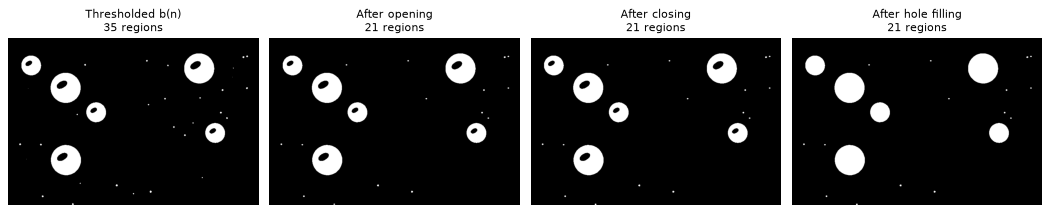

In [9]:
res3 = run(syn_imgs["case3_noisy_glare.jpg"], cfg)
steps = [(res3.mask_raw, "Thresholded b(n)"), (res3.mask_open, "After opening"),
         (res3.mask_closed, "After closing"), (res3.mask_clean, "After hole filling")]
gt_mask3 = cv2.resize((pre.load_image(SYN / gt_syn["case3_noisy_glare.jpg"]["mask"])[..., 0] > 127).astype(np.uint8),
                      res3.mask_clean.shape[::-1], interpolation=cv2.INTER_NEAREST)
table([{"step": t, "regions": lab.count_components(m), "foreground pixels": int(m.sum()),
        "IoU with GT mask": iou(m, gt_mask3)} for m, t in steps])
show([(m, f"{t}\n{lab.count_components(m)} regions") for m, t in steps], cols=4, size=3.3)

## 5. Stage 3 – Region labeling, splitting and features

### 5.1 Two-pass labeling (own implementation) vs OpenCV

Pass 1 scans the image and records label equivalences in a union-find table; pass 2 replaces each label by its class representative. Regions smaller than $A_{min} = \max(100,\ 0.0003\,MN)$ px are dropped.

4-connectivity: own 21 regions (24.7 ms) | OpenCV 21 regions (1.3 ms) | same partition: True


8-connectivity: own 21 regions (30.0 ms) | OpenCV 21 regions (0.6 ms) | same partition: True
A_min = 128 px: 21 regions -> 6 objects


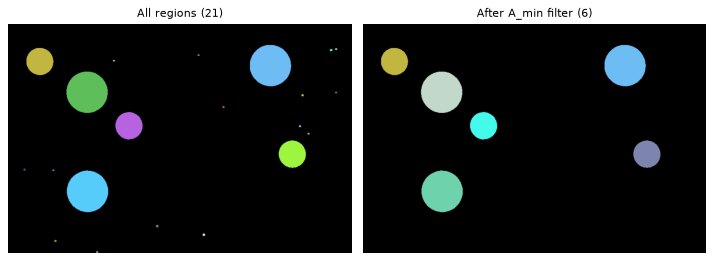

In [10]:
mask = res3.mask_clean
for conn in (4, 8):
    (l_own, n_own), t_own = timed(lab.label, mask, conn, "numpy", repeat=1)
    (l_cv, n_cv), t_cv = timed(lab.label, mask, conn, "opencv", repeat=1)
    print(f"{conn}-connectivity: own {n_own} regions ({t_own:.1f} ms) | OpenCV {n_cv} regions ({t_cv:.1f} ms) | "
          f"same partition: {lab.same_partition(l_own, l_cv)}")

labels, n = lab.label(mask, 4)
a_min = max(cfg.min_area_px, int(cfg.min_area_frac * mask.size))
kept, n_kept = lab.remove_small(labels, a_min)
print(f"A_min = {a_min} px: {n} regions -> {n_kept} objects")
show([(colorize_labels(labels), f"All regions ({n})"), (colorize_labels(kept), f"After A_min filter ({n_kept})")],
     size=4.5)

### 5.2 Splitting touching objects with distance transform + watershed (Case 4)

Two overlapping coins form **one** connected region. Such a region is concave at the contact point, so its **solidity** $A/A_{hull}$ is low (< 0.94). For these regions only, the peaks of the distance transform become markers for the watershed.

Without watershed: 5 objects | with watershed: 6 objects (ground truth 6)
Split log: [{'label': 3, 'solidity': 0.9, 'parts': 2}]
Merged region: area 6211 px, solidity 0.900, circularity 0.630


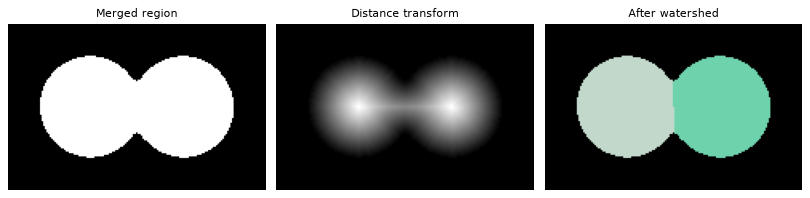

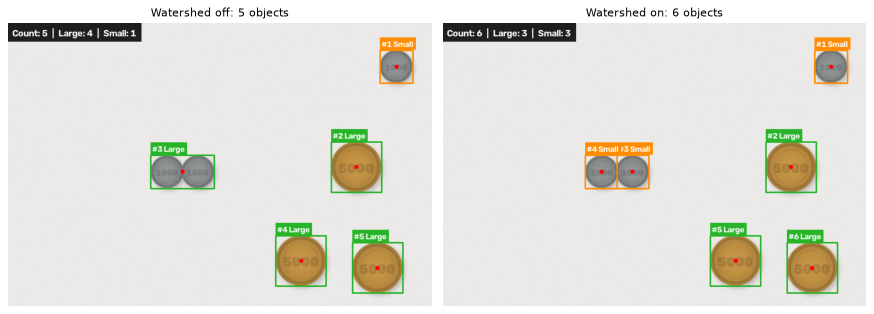

In [11]:
img4 = syn_imgs["case4_overlapping.jpg"]
res4_off = run(img4, replace(cfg, split_touching=False))
res4_on = run(img4, cfg)
print(f"Without watershed: {len(res4_off.objects)} objects | with watershed: {len(res4_on.objects)} objects "
      f"(ground truth {gt_syn['case4_overlapping.jpg']['count']})")
print("Split log:", res4_on.stats["split"])

merged = min(res4_off.objects, key=lambda o: o.solidity)   # the merged (concave) region
print(f"Merged region: area {merged.area} px, solidity {merged.solidity:.3f}, circularity {merged.circularity:.3f}")
region = (res4_off.labels == merged.label).astype(np.uint8)
dist = cv2.distanceTransform(region, cv2.DIST_L2, 5)
y, x, h, w = merged.y, merged.x, merged.h, merged.w
zoom = lambda im: im[max(0, y - 20):y + h + 20, max(0, x - 20):x + w + 20]
show([(zoom(region), "Merged region"), (zoom((dist / dist.max() * 255).astype(np.uint8)), "Distance transform"),
      (zoom(colorize_labels(res4_on.labels)), "After watershed")], size=3.4)
show([(draw_detections(res4_off.image, res4_off.objects, res4_off.class_info), f"Watershed off: {len(res4_off.objects)} objects"),
      (draw_detections(res4_on.image, res4_on.objects, res4_on.class_info), f"Watershed on: {len(res4_on.objects)} objects")],
     size=5.5)

### 5.3 Geometric features

For every object: area $A$, centroid, bounding box, perimeter $L=\sum \Delta L$ along the contour, boundary diameter (farthest pair of convex-hull points), major-axis orientation, circularity $4\pi A/L^2$, solidity and equivalent diameter.

In [12]:
table([{"ID": o.id, "centroid": f"({o.cx:.0f}, {o.cy:.0f})", "box (x, y, w, h)": f"({o.x}, {o.y}, {o.w}, {o.h})",
        "area A": o.area, "perimeter L": round(o.perimeter, 1), "diameter": round(o.diameter, 1),
        "orientation°": round(o.orientation, 1), "circularity": o.circularity, "solidity": o.solidity,
        "eq. diameter": round(o.eq_diameter, 1), "class": o.cls} for o in res1.objects])

ID,centroid,"box (x, y, w, h)",area A,perimeter L,diameter,orientation°,circularity,solidity,eq. diameter,class
1,"(86, 121)","(39, 74, 96, 96)",7254,315.000,96.400,59.400,0.919,0.990,96.100,Large
2,"(222, 184)","(191, 153, 63, 63)",3132,205.800,63.300,78.200,0.929,0.987,63.100,Small
3,"(661, 233)","(630, 202, 63, 63)",3133,205.800,63.300,78.200,0.929,0.986,63.200,Small
4,"(382, 272)","(334, 224, 96, 97)",7261,316.400,96.300,77.400,0.911,0.989,96.200,Large
5,"(239, 412)","(208, 380, 63, 64)",3141,206.700,63.400,52.000,0.924,0.986,63.200,Small
6,"(572, 451)","(525, 404, 96, 96)",7251,315.000,96.300,34.800,0.918,0.990,96.100,Large


## 6. Stage 4 – Large/Small classification

Decision rule: $A_m \ge T_{area} \Rightarrow$ Large, otherwise Small. $T_{area}$ is chosen by **1-D Otsu on the set of areas** (maximum between-class variance) instead of the mean area, which is biased when the two groups have different sizes or a merged blob is present. When $A_{max}/A_{min} < 1.3$ there is only one size group and no split is made.

Areas (px): [3132, 3133, 3141, 7251, 7254, 7261]
T_area: 1-D Otsu = 5196 | mean = 5195 | largest gap = 5196
Result: {'method': 'otsu', 'threshold': np.float64(5196.0), 'warning': None, 'n_large': 3, 'n_small': 3}


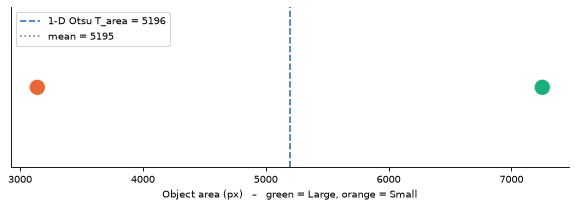

Only small coins: {'method': 'otsu', 'threshold': None, 'warning': 'A_max/A_min = 1.00 < 1.3: single size group, no Large/Small split', 'n_large': 0, 'n_small': 0, 'n_same': 3}


In [13]:
areas = np.array([o.area for o in res1.objects])
T_otsu1d, T_mean, T_gap = clf.otsu_1d(areas), areas.mean(), clf.largest_gap(areas)
print(f"Areas (px): {sorted(areas.tolist())}")
print(f"T_area: 1-D Otsu = {T_otsu1d:.0f} | mean = {T_mean:.0f} | largest gap = {T_gap:.0f}")
print(f"Result: {res1.class_info}")

fig, ax = plt.subplots(figsize=(9, 2.6))
colors = [GREEN if o.cls == "Large" else ORANGE for o in res1.objects]
ax.scatter(areas, np.zeros_like(areas), s=220, c=colors, edgecolors="white", zorder=3)
ax.axvline(T_otsu1d, color=BLUE, ls="--", label=f"1-D Otsu T_area = {T_otsu1d:.0f}")
ax.axvline(T_mean, color="gray", ls=":", label=f"mean = {T_mean:.0f}")
ax.set_yticks([])
ax.set_xlabel("Object area (px)   –   green = Large, orange = Small")
ax.legend(loc="upper left")
plt.show()

# Only one size group -> the classifier refuses to split
small_only = copy.deepcopy([o for o in res1.objects if o.cls == "Small"])
print("Only small coins:", clf.classify(small_only, cfg))

## 7. Full pipeline on the 4 synthetic cases

`run(image, Config())` executes all four stages. Each result is compared with the ground truth: object count, Large/Small numbers and mask IoU.

case,AOD before,AOD after,T*,raw regions,after morphology,split,count,GT,Large/Small,count ok,class ok,mask IoU,time (ms)
case1_ideal,226.600,235.200,148,6,6,0,6,6,3/3,✓,✓,0.972,146.000
case2_low_contrast,92.300,227.200,143,6,6,0,6,6,3/3,✓,✓,0.971,169.000
case3_noisy_glare,225.100,219.600,143,35,21,0,6,6,3/3,✓,✓,0.961,190.900
case4_overlapping,226.600,235.100,147,5,5,1,6,6,3/3,✓,✓,0.972,145.900


All 4 synthetic cases: correct count and correct Large/Small split.


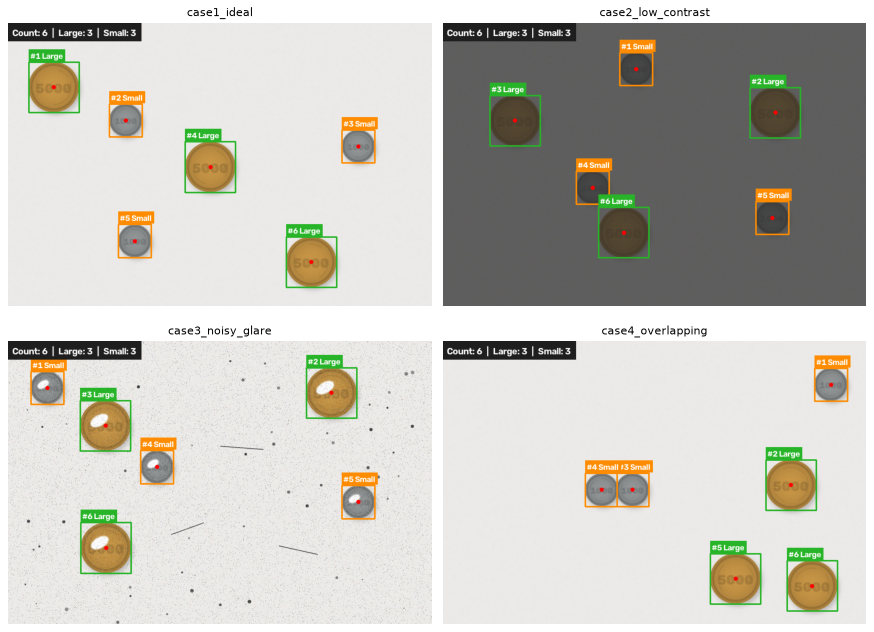

In [14]:
syn_rows, syn_res = [], {}
for name, img in syn_imgs.items():
    res = run(img, cfg)
    ev = evaluate_image(res, gt_syn[name], SYN)
    syn_res[name] = res
    syn_rows.append({"case": name.replace(".jpg", ""), "AOD before": round(res.aod_before, 1),
                     "AOD after": round(res.aod_after, 1), "T*": res.seg_info["T"],
                     "raw regions": res.stats["regions_raw"], "after morphology": res.stats["regions_after_morph"],
                     "split": sum(s["parts"] - 1 for s in res.stats["split"]),
                     "count": len(res.objects), "GT": ev["gt_count"],
                     "Large/Small": f"{res.class_info['n_large']}/{res.class_info['n_small']}",
                     "count ok": ev["count_ok"], "class ok": ev["class_ok"], "mask IoU": ev["mask_iou"],
                     "time (ms)": round(res.timings["total"], 1)})
table(syn_rows)
assert all(r["count ok"] and r["class ok"] for r in syn_rows), "a synthetic case failed"
print("All 4 synthetic cases: correct count and correct Large/Small split.")
show([(draw_detections(r.image, r.objects, r.class_info), n.replace(".jpg", "")) for n, r in syn_res.items()],
     cols=2, size=5.5)

Stage-by-stage view of every case (input → preprocessing → threshold → morphology → labels → result):

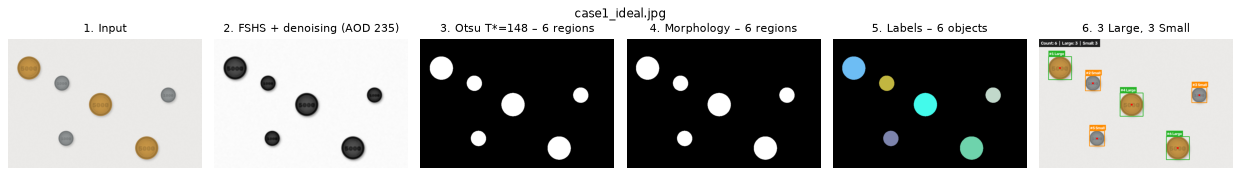

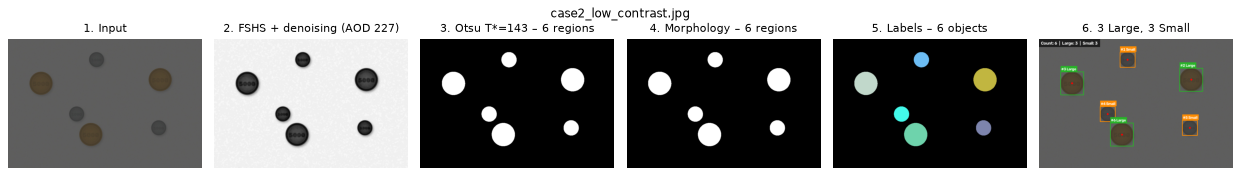

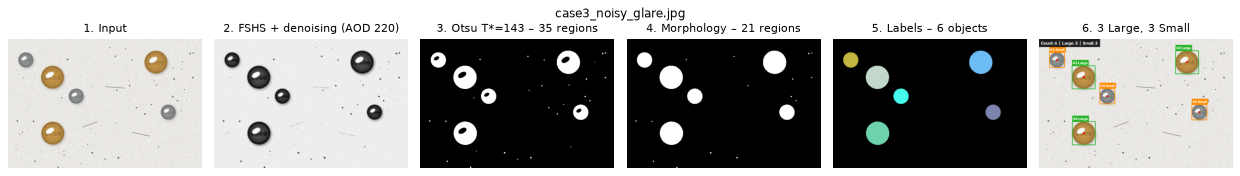

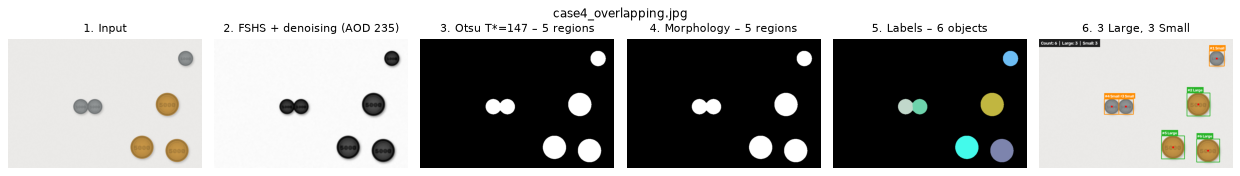

In [15]:
for name, res in syn_res.items():
    st = res.stats
    show([(res.image, "1. Input"), (res.smooth, f"2. FSHS + denoising (AOD {res.aod_after:.0f})"),
          (res.mask_raw, f"3. Otsu T*={res.seg_info['T']} – {st['regions_raw']} regions"),
          (res.mask_clean, f"4. Morphology – {st['regions_after_morph']} regions"),
          (colorize_labels(res.labels), f"5. Labels – {st['n_obj']} objects"),
          (draw_detections(res.image, res.objects, res.class_info),
           f"6. {res.class_info['n_large']} Large, {res.class_info['n_small']} Small")],
         cols=6, size=2.6, suptitle=name)

## 8. Verification: own implementations vs OpenCV

Every core algorithm implemented from scratch must give the same result as the OpenCV function (Case 3 image, 800×534; same steps as `tools/verify_impl.py`). The Gaussian may differ by 1 gray level because of rounding.

In [16]:
g = pre.rgb_to_gray(img3)
checks = []
m1, t1 = timed(pre.median_filter, g, 5, "numpy"); m2, t2 = timed(pre.median_filter, g, 5, "opencv")
checks.append(("Median filter 5×5", f"max |difference| = {np.abs(m1.astype(int) - m2).max()}", t1, t2))
s1, t1 = timed(pre.gaussian_filter, m1, 5, 1.0, "numpy"); s2, t2 = timed(pre.gaussian_filter, m1, 5, 1.0, "opencv")
checks.append(("Gaussian filter 5×5", f"max |difference| = {np.abs(s1.astype(int) - s2).max()}", t1, t2))
(T1, _), t1 = timed(seg.otsu_threshold, s1, "numpy"); (T2, _), t2 = timed(seg.otsu_threshold, s1, "opencv")
checks.append(("Otsu threshold", f"T* own = {T1}, OpenCV = {T2}", t1, t2))
mask, _ = seg.segment(s1, cfg)
se = morph.structuring_element(5)
e1, t1 = timed(morph.erode, mask, se, "numpy"); e2, t2 = timed(morph.erode, mask, se, "opencv")
checks.append(("Erosion", f"identical = {np.array_equal(e1, e2)}", t1, t2))
d1, t1 = timed(morph.dilate, mask, se, "numpy"); d2, t2 = timed(morph.dilate, mask, se, "opencv")
checks.append(("Dilation", f"identical = {np.array_equal(d1, d2)}", t1, t2))
for conn in (4, 8):
    (l1, n1), t1 = timed(lab.label, mask, conn, "numpy", repeat=1)
    (l2, n2), t2 = timed(lab.label, mask, conn, "opencv", repeat=1)
    checks.append((f"{conn}-connected labeling", f"regions {n1} / {n2}, same partition = {lab.same_partition(l1, l2)}",
                   t1, t2))
table([{"algorithm": a, "comparison": c, "own (ms)": round(x, 2), "OpenCV (ms)": round(y, 2)} for a, c, x, y in checks])

algorithm,comparison,own (ms),OpenCV (ms)
Median filter 5×5,max |difference| = 0,100.720,0.580
Gaussian filter 5×5,max |difference| = 1,22.220,0.100
Otsu threshold,"T* own = 186, OpenCV = 186",1.640,1.780
Erosion,identical = True,0.720,0.110
Dilation,identical = True,0.660,0.100
4-connected labeling,"regions 35 / 35, same partition = True",22.390,0.940
8-connected labeling,"regions 35 / 35, same partition = True",26.340,0.830


## 9. Real photos: why the baseline fails and how the real-image branch works

**Baseline A** is the same pipeline as on the synthetic images (Otsu on the gray image). On real photos the coins cover only ~2% of the image and the background is not uniform (shading, texture, table edges), so the global threshold splits the *background* instead of separating the coins.

**Final configuration V** (`--preset real`) uses a change-detection idea:
1. estimate the background $B(n)$ with a large median filter (window = 0.15 × short side);
2. difference image $D(n) = \lVert I_{Lab}(n) - B(n) \rVert$, thresholded with the **Triangle** method (one peak + long tail);
3. clear regions touching the border; watershed only on regions with circularity ≥ 0.35;
4. shape filter: circularity ≥ 0.6, area ≤ 5% of the image, area ≥ 0.25 × median object area.

Configuration V overrides: {'seg_method': 'bgsub', 'bg_threshold': 'triangle', 'bg_color': True, 'bg_kernel_frac': 0.15, 'clear_border': True, 'split_min_circularity': 0.35, 'min_area_rel_median': 0.25, 'min_circularity': 0.6, 'max_area_frac': 0.05}


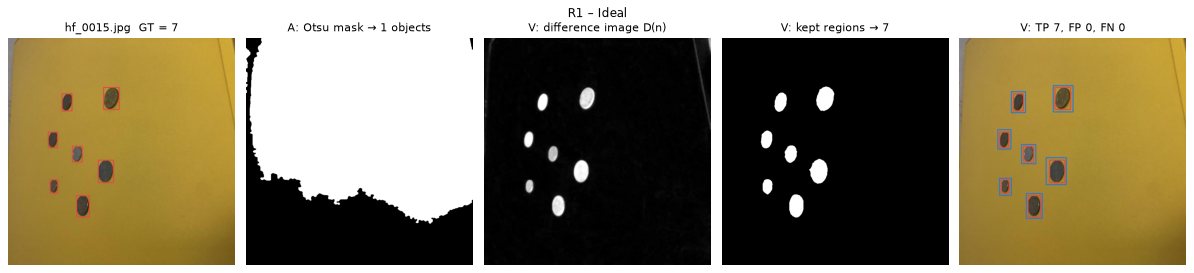

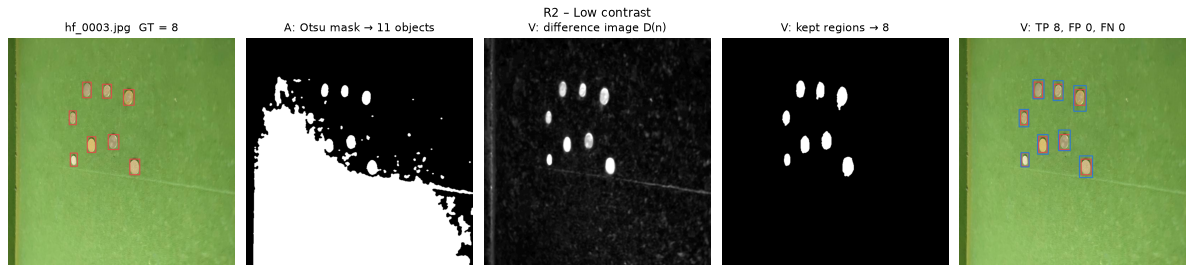

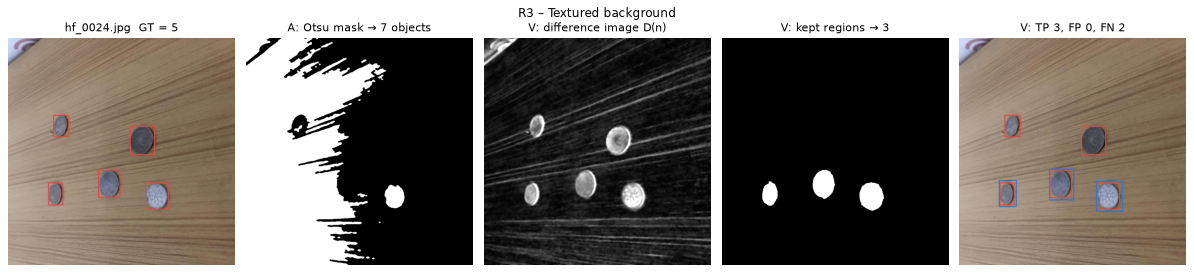

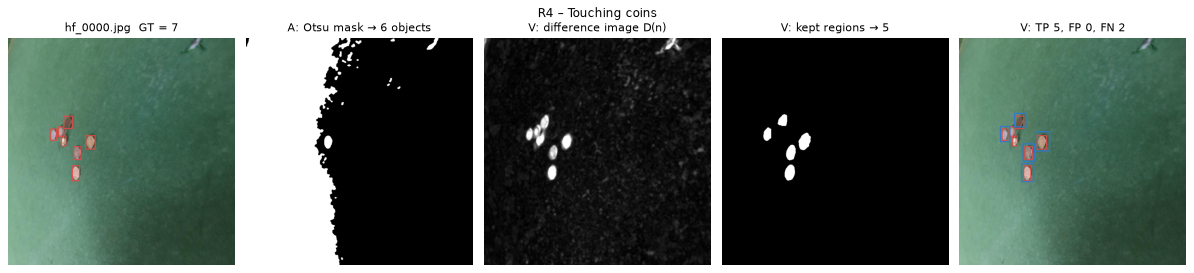

In [17]:
BASELINE = Config(backend="opencv", split_min_circularity=0.0)      # configuration A
FINAL = replace(Config(backend="opencv"), **REAL_PRESET)            # configuration V
print("Configuration V overrides:", REAL_PRESET)

for k, name in examples.items():
    img = pre.load_image(REAL / name)
    rA, rV = run(img, BASELINE), run(img, FINAL)
    eA, eV = evaluate_image(rA, gt_real[name]), evaluate_image(rV, gt_real[name])
    d = rV.smooth.astype(np.float64)
    d_vis = np.clip(d / max(1.0, np.percentile(d, 99.5)) * 255, 0, 255).astype(np.uint8)
    show([(draw_boxes(rA.image, gt_real[name]["boxes"], scale=rA.scale), f"{name}  GT = {eA['gt_count']}"),
          (rA.mask_clean, f"A: Otsu mask → {len(rA.objects)} objects"),
          (d_vis, "V: difference image D(n)"),
          ((rV.labels > 0).astype(np.uint8), f"V: kept regions → {len(rV.objects)}"),
          (draw_boxes(rV.image, gt_real[name]["boxes"], rV.objects, rV.scale),
           f"V: TP {eV['tp']}, FP {eV['fp']}, FN {eV['fn']}")],
         cols=5, size=3.0, suptitle=CASE_NAMES[k])

## 10. Evaluation on the real test split (480 images, 3,386 coins)

Metrics:
* **Exact count accuracy** – fraction of images with $\hat N = N$; **±1** – fraction with $|\hat N - N| \le 1$; **MAE** – mean $|\hat N - N|$.
* **Object-level Precision / Recall / F1** – a prediction is a true positive when its centroid falls inside a not-yet-matched ground-truth box (greedy one-to-one matching).

Both configurations are run in parallel worker processes (`tools/experiment_real.run_one`, the same function used for the report).

In [18]:
from experiment_real import run_one     # module-level function, so it can run in worker processes


def evaluate_split(overrides, names, workers=N_WORKERS):
    jobs = [(REAL / n, gt_real[n], overrides) for n in names]
    try:
        with ProcessPoolExecutor(workers) as ex:
            rows = list(ex.map(run_one, jobs, chunksize=8))
    except Exception as e:                   # e.g. no multiprocessing available -> run sequentially
        print("Parallel run failed, running sequentially:", e)
        rows = [run_one(j) for j in jobs]
    for n, r in zip(names, rows):
        r["image"] = n
    return rows


test_names = split["test"]
t0 = time.perf_counter()
rows_A = evaluate_split({}, test_names)              # A: baseline
rows_V = evaluate_split(REAL_PRESET, test_names)     # V: final configuration
print(f"Evaluated 2 × {len(test_names)} images in {time.perf_counter() - t0:.0f} s")

agg_A, agg_V = aggregate(rows_A), aggregate(rows_V)
REPORT = {"A": {"exact": 12.9, "f1": 0.450}, "V": {"exact": 65.4, "f1": 0.940}}    # numbers in the report
metric_rows = []
for name, agg in (("A – baseline (Otsu, gray)", agg_A), ("V – final (real-image branch)", agg_V)):
    key = name[0]
    same = (round(agg["count_exact_acc"] * 100, 1) == REPORT[key]["exact"] and round(agg["f1"], 3) == REPORT[key]["f1"])
    metric_rows.append({"configuration": name, "exact count %": round(agg["count_exact_acc"] * 100, 1),
                        "within ±1 %": round(agg["count_within1_acc"] * 100, 1), "MAE": round(agg["count_mae"], 2),
                        "TP": agg["tp"], "FP": agg["fp"], "FN": agg["fn"], "precision": agg["precision"],
                        "recall": agg["recall"], "F1": agg["f1"], "matches report": same})
table(metric_rows)

Evaluated 2 × 480 images in 21 s


configuration,exact count %,within ±1 %,MAE,TP,FP,FN,precision,recall,F1,matches report
"A – baseline (Otsu, gray)",12.900,32.900,4.580,1727,2561,1659,0.403,0.510,0.450,✓
V – final (real-image branch),65.400,84.200,0.770,3247,277,139,0.921,0.959,0.940,✓


## 11. Results per real-image case and counting-error distribution

case,images,A exact %,A F1,V exact %,V ±1 %,V MAE,V precision,V recall,V F1
R1 – Ideal,232,12.900,0.676,84.100,94.000,0.330,0.966,0.988,0.977
R2 – Low contrast,88,5.700,0.181,52.300,77.300,1.250,0.855,0.963,0.906
R3 – Textured background,132,19.700,0.226,50.800,78.000,0.980,0.894,0.943,0.918
R4 – Touching coins,28,3.600,0.351,21.400,53.600,1.960,0.865,0.754,0.805
All,480,12.900,0.450,65.400,84.200,0.770,0.921,0.959,0.940


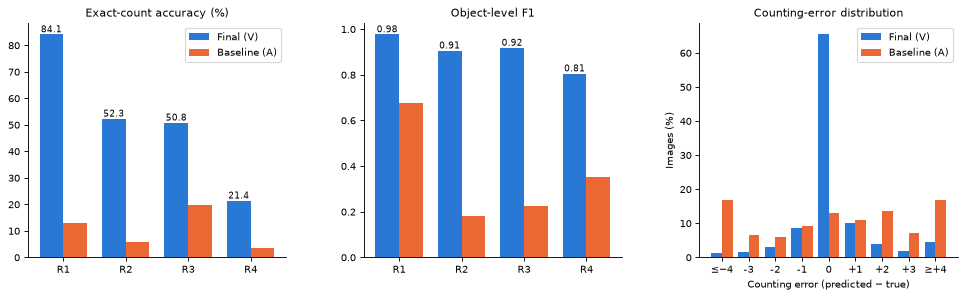

In [19]:
def metrics(rows):
    e = np.array([r["count_error"] for r in rows])
    tp, fp, fn = (sum(r[k] for r in rows) for k in ("tp", "fp", "fn"))
    p, rc = tp / max(1, tp + fp), tp / max(1, tp + fn)
    return {"images": len(rows), "exact %": round(float(np.mean(e == 0)) * 100, 1),
            "±1 %": round(float(np.mean(np.abs(e) <= 1)) * 100, 1), "MAE": round(float(np.mean(np.abs(e))), 2),
            "precision": p, "recall": rc, "F1": 2 * p * rc / (p + rc) if p + rc else 0.0}


case_rows, per_case = [], {}
for k, cname in CASE_NAMES.items():
    mA = metrics([r for r in rows_A if cases[r["image"]] == k])
    mV = metrics([r for r in rows_V if cases[r["image"]] == k])
    per_case[k] = (mA, mV)
    case_rows.append({"case": cname, "images": mV["images"], "A exact %": mA["exact %"], "A F1": mA["F1"],
                      "V exact %": mV["exact %"], "V ±1 %": mV["±1 %"], "V MAE": mV["MAE"],
                      "V precision": mV["precision"], "V recall": mV["recall"], "V F1": mV["F1"]})
mA, mV = metrics(rows_A), metrics(rows_V)
case_rows.append({"case": "All", "images": mV["images"], "A exact %": mA["exact %"], "A F1": mA["F1"],
                  "V exact %": mV["exact %"], "V ±1 %": mV["±1 %"], "V MAE": mV["MAE"],
                  "V precision": mV["precision"], "V recall": mV["recall"], "V F1": mV["F1"]})
table(case_rows)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"wspace": 0.3})
x, w = np.arange(len(CASE_NAMES)), 0.38
labels = [CASE_NAMES[k].split(" – ")[0] for k in CASE_NAMES]
for ax, key, title in ((axs[0], "exact %", "Exact-count accuracy (%)"), (axs[1], "F1", "Object-level F1")):
    a = [per_case[k][0][key] for k in CASE_NAMES]
    v = [per_case[k][1][key] for k in CASE_NAMES]
    ax.bar(x - w / 2, v, w, color=BLUE, label="Final (V)")
    ax.bar(x + w / 2, a, w, color=ORANGE, label="Baseline (A)")
    for xi, val in zip(x - w / 2, v):
        ax.text(xi, val, f"{val:.1f}" if key == "exact %" else f"{val:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, labels)
    ax.set_title(title)
axs[0].legend(loc="upper right")

bins = np.arange(-4, 5)
for rows, color, name, off in ((rows_V, BLUE, "Final (V)", -0.2), (rows_A, ORANGE, "Baseline (A)", 0.2)):
    e = np.clip([r["count_error"] for r in rows], -4, 4)
    axs[2].bar(bins + off, [np.mean(e == b) * 100 for b in bins], 0.4, color=color, label=name)
axs[2].set_xticks(bins, ["≤−4"] + [f"{b:+d}" if b else "0" for b in bins[1:-1]] + ["≥+4"])
axs[2].set_xlabel("Counting error (predicted − true)")
axs[2].set_ylabel("Images (%)")
axs[2].set_title("Counting-error distribution")
axs[2].legend()
plt.show()

## 12. Ablation on the dev split

How much each step of the real-image branch contributes. Parameters were **selected on dev**, so this table explains the design choices; the test numbers in section 10 are the unbiased ones. Set `RUN_ABLATION = False` to skip this section (about 2–4 minutes).

configuration,exact %,±1 %,MAE,precision,recall,F1,matches saved run
A. Baseline: Otsu on gray image,12.500,33.300,3.780,0.472,0.567,0.515,✓
G. Background diff. (Lab) + Triangle,9.400,17.100,9.220,0.431,0.987,0.600,✓
"I. G + shape filter (circ>=0.5, A<=5%)",12.500,22.900,6.840,0.502,0.981,0.664,✓
L. I + border clearing,44.600,64.800,1.520,0.817,0.978,0.891,✓
M. L + watershed only if circ>=0.35,50.000,70.400,1.170,0.863,0.968,0.912,✓
N. M + drop crumbs < 0.25 x median,66.000,83.500,0.690,0.925,0.966,0.945,✓
V. N + window 0.15 + circ>=0.6 [FINAL],70.000,87.900,0.580,0.944,0.963,0.954,✓


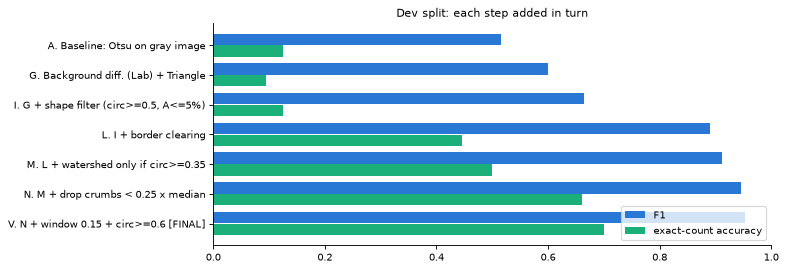

In [20]:
RUN_ABLATION = True
from experiment_real import EXPERIMENTS

KEY = ["A", "G", "I", "L", "M", "N", "V"]
if RUN_ABLATION:
    dev_names = split["dev"]
    saved_dev = json.loads((ROOT / "outputs" / "experiment_hf_coins_dev.json").read_text(encoding="utf-8"))
    ablation = []
    for label, overrides in EXPERIMENTS:
        if label.split(".")[0] not in KEY:
            continue
        agg = aggregate(evaluate_split(overrides, dev_names))
        ref = saved_dev[label]
        ablation.append({"configuration": label, "exact %": round(agg["count_exact_acc"] * 100, 1),
                         "±1 %": round(agg["count_within1_acc"] * 100, 1), "MAE": round(agg["count_mae"], 2),
                         "precision": agg["precision"], "recall": agg["recall"], "F1": agg["f1"],
                         "matches saved run": agg["tp"] == ref["tp"] and agg["fp"] == ref["fp"] and agg["fn"] == ref["fn"]})
    table(ablation)

    fig, ax = plt.subplots(figsize=(9, 3.6))
    y = np.arange(len(ablation))[::-1]
    ax.barh(y + 0.2, [r["F1"] for r in ablation], 0.38, color=BLUE, label="F1")
    ax.barh(y - 0.2, [r["exact %"] / 100 for r in ablation], 0.38, color=GREEN, label="exact-count accuracy")
    ax.set_yticks(y, [r["configuration"] for r in ablation])
    ax.set_xlim(0, 1)
    ax.set_title("Dev split: each step added in turn")
    ax.legend(loc="lower right")
    plt.show()

## 13. Successes and failures (configuration V, test split)

Red = ground truth, blue = prediction. The three largest errors are all **over-counts**: small unlabeled objects piled in a corner of the mat are round and coin-sized, so the shape filter keeps them. The other typical failure is the opposite (under-count): clusters of touching coins, or coins merged with shadows or texture, form irregular regions that are not split by watershed and are then removed by the shape filter (case R4).

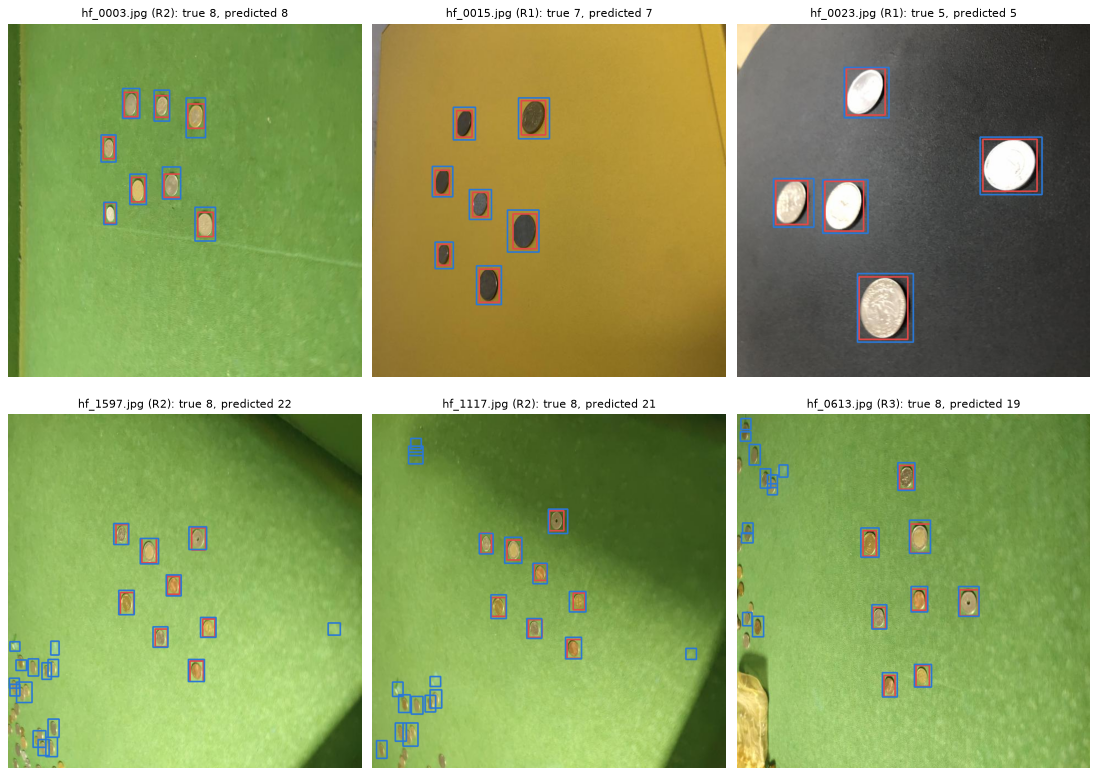

In [21]:
by_err = sorted(rows_V, key=lambda r: (abs(r["count_error"]), r["image"]))
good = [r for r in by_err if r["count_error"] == 0 and r["fp"] == 0][:3]
bad = sorted(rows_V, key=lambda r: (-abs(r["count_error"]), r["image"]))[:3]
panels = []
for r in good + bad:
    res = run(pre.load_image(REAL / r["image"]), FINAL)
    tag = CASE_NAMES[cases[r["image"]]].split(" – ")[0]
    panels.append((draw_boxes(res.image, gt_real[r["image"]]["boxes"], res.objects, res.scale),
                   f"{r['image']} ({tag}): true {r['gt_count']}, predicted {len(res.objects)}"))
show(panels, cols=3, size=4.6)

## 14. Run time: own NumPy implementations vs OpenCV

Both backends give the same detections; OpenCV is faster because its filters and labeling are written in optimized C++. Timings depend on the machine.

In [22]:
STAGES = ["1_preprocess", "2_segmentation", "3_label_features", "4_classify"]
timing, counts_by_image = {}, {}
for backend in ("numpy", "opencv"):
    c = replace(FINAL, backend=backend)
    acc = {s: [] for s in STAGES + ["total"]}
    for n in test_names[:20]:
        res = run(pre.load_image(REAL / n), c)
        for s in acc:
            acc[s].append(res.timings[s])
        counts_by_image.setdefault(n, []).append(len(res.objects))
    timing[backend] = {s: float(np.mean(v)) for s, v in acc.items()}
same = all(a == b for a, b in counts_by_image.values())
table([{"backend": b, **{s: round(timing[b][s], 1) for s in STAGES}, "total (ms/image)": round(timing[b]["total"], 1)}
       for b in ("numpy", "opencv")])
print(f"Same object counts on all 20 images with both backends: {same}")

backend,1_preprocess,2_segmentation,3_label_features,4_classify,total (ms/image)
numpy,138.500,5.500,35.900,0.100,180.000
opencv,36.100,3.100,18.300,0.100,57.500


Same object counts on all 20 images with both backends: True


## 15. Try it on your own photo

Set `MY_IMAGE` to the path of a photo (e.g. coins of two sizes on white paper, phone parallel to the table, flash off). Use `Config()` for a plain, uniform background and `FINAL` for a real, non-uniform background. Large/Small needs two size groups whose areas differ by at least 1.3×.

case1_ideal.jpg: 6 objects – {'method': 'otsu', 'threshold': np.float64(5196.0), 'warning': None, 'n_large': 3, 'n_small': 3}


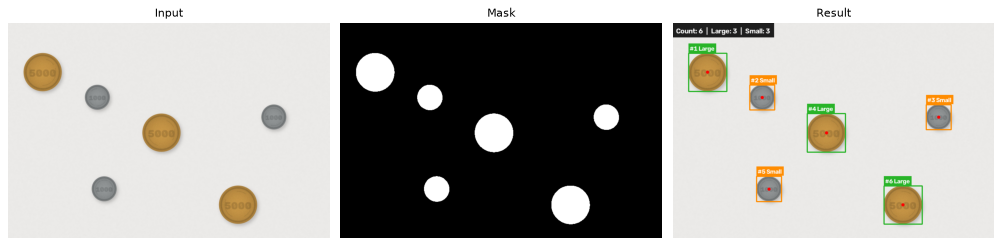

In [23]:
MY_IMAGE = None            # e.g. ROOT / "data" / "raw" / "my_coins.jpg"
MY_CONFIG = Config()       # or FINAL for real, non-uniform backgrounds

path = Path(MY_IMAGE) if MY_IMAGE else SYN / "case1_ideal.jpg"      # falls back to a synthetic example
res = run(pre.load_image(path), MY_CONFIG)
print(f"{path.name}: {len(res.objects)} objects – {res.class_info}")
show([(res.image, "Input"), (res.mask_clean, "Mask"),
      (draw_detections(res.image, res.objects, res.class_info), "Result")], size=4.2)

## 16. Summary

In [24]:
syn_ok = sum(r["count ok"] and r["class ok"] for r in syn_rows)
print("SYNTHETIC CASES")
print(f"  {syn_ok}/4 cases with correct count and Large/Small split, "
      f"mask IoU {min(r['mask IoU'] for r in syn_rows):.3f}–{max(r['mask IoU'] for r in syn_rows):.3f}")
print("REAL TEST SPLIT (480 images, 3,386 coins)")
for name, agg in (("Baseline A", agg_A), ("Final V   ", agg_V)):
    print(f"  {name}: exact {agg['count_exact_acc'] * 100:.1f}%  ±1 {agg['count_within1_acc'] * 100:.1f}%  "
          f"MAE {agg['count_mae']:.2f}  P {agg['precision']:.3f}  R {agg['recall']:.3f}  F1 {agg['f1']:.3f}")
print("PER CASE (V): " + "  ".join(f"{CASE_NAMES[k].split(' – ')[0]} F1 {per_case[k][1]['F1']:.3f}" for k in CASE_NAMES))
print(f"RUN TIME: {timing['opencv']['total']:.0f} ms/image (OpenCV), {timing['numpy']['total']:.0f} ms/image (own NumPy)")

SYNTHETIC CASES
  4/4 cases with correct count and Large/Small split, mask IoU 0.961–0.972
REAL TEST SPLIT (480 images, 3,386 coins)
  Baseline A: exact 12.9%  ±1 32.9%  MAE 4.58  P 0.403  R 0.510  F1 0.450
  Final V   : exact 65.4%  ±1 84.2%  MAE 0.77  P 0.921  R 0.959  F1 0.940
PER CASE (V): R1 F1 0.977  R2 F1 0.906  R3 F1 0.918  R4 F1 0.805
RUN TIME: 58 ms/image (OpenCV), 180 ms/image (own NumPy)


**Conclusions**

* On controlled synthetic scenes the classical pipeline (FSHS → median/Gaussian → Otsu → morphology → labeling → watershed → 1-D Otsu on areas) counts and classifies every object correctly.
* FSHS is essential for a fixed threshold but does not change Otsu, which is invariant to linear gray-level transforms.
* On real photos a global threshold fails because the coins are small and the background is not uniform. Background estimation + a Lab difference image + Triangle thresholding + shape filtering raises the exact-count accuracy from about 13% to about 65% and F1 from 0.45 to 0.94 on the held-out test split.
* The main remaining failure is clusters of touching coins (case R4): the merged region is too irregular to be split by watershed.
* Large/Small classification on real photos needs self-captured images with size labels taken at a fixed camera height.